# CSOT Quant Finance & Research Track (Week 1 Task)

**Name:** Abhineet Pandey  
**Asset Evaluated:** SPY (SPDR S&P 500 ETF Trust)  

---

In [32]:
import yfinance as yf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

# Global ticker mapping to avoid hardcoding down the line
TICKER = "SPY"

## Part 1: Return Profile and Benchmark

We pull 3 years of daily price history data for our baseline liquid asset using `yfinance`. Daily log returns are calculated instead of raw price movements to correctly represent corporate actions and volatility compounding over multiple periods.

---

In [33]:
# ==============================================================================
# 1a. BENCHMARK METRICS
# ==============================================================================
# Pull 3 years of daily historical data for SPY
df = yf.download(TICKER, start="2023-01-01", end="2026-01-01")

# FLATTEN MULTI-LEVEL COLUMNS IMMEDIATELY (Fixes the KeyError permanently)
if isinstance(df.columns, pd.MultiIndex):
    df.columns = [col[0] for col in df.columns]

# Extract log returns array using clean, flattened string indices
df['Log_Return'] = np.log(df['Close'] / df['Close'].shift(1))
df = df.dropna().copy()
rets = df['Log_Return']

# Metric Calculations
mean_daily_return = rets.mean()
annualized_return = mean_daily_return * 252

daily_volatility = rets.std()
annualized_volatility = daily_volatility * np.sqrt(252)

annualized_sharpe = annualized_return / annualized_volatility

# Build Equity Curve to calculate Max Drawdown
# (We save Equity_Curve to df so Cell 15 can find it later!)
df['Equity_Curve'] = np.exp(rets.cumsum())
running_peak = df['Equity_Curve'].cummax()
drawdown = (df['Equity_Curve'] - running_peak) / running_peak
max_drawdown = drawdown.min()

print(f"=== 1a. BENCHMARK REPORT FOR {TICKER} ===")
print(f"Annualized Return:     {annualized_return:.2%}")
print(f"Annualized Volatility: {annualized_volatility:.2%}")
print(f"Annualized Sharpe:     {annualized_sharpe:.2f}")
print(f"Maximum Drawdown:      {max_drawdown:.2%}")

[*********************100%***********************]  1 of 1 completed

=== 1a. BENCHMARK REPORT FOR SPY ===
Annualized Return:     20.87%
Annualized Volatility: 15.28%
Annualized Sharpe:     1.37
Maximum Drawdown:      -18.76%


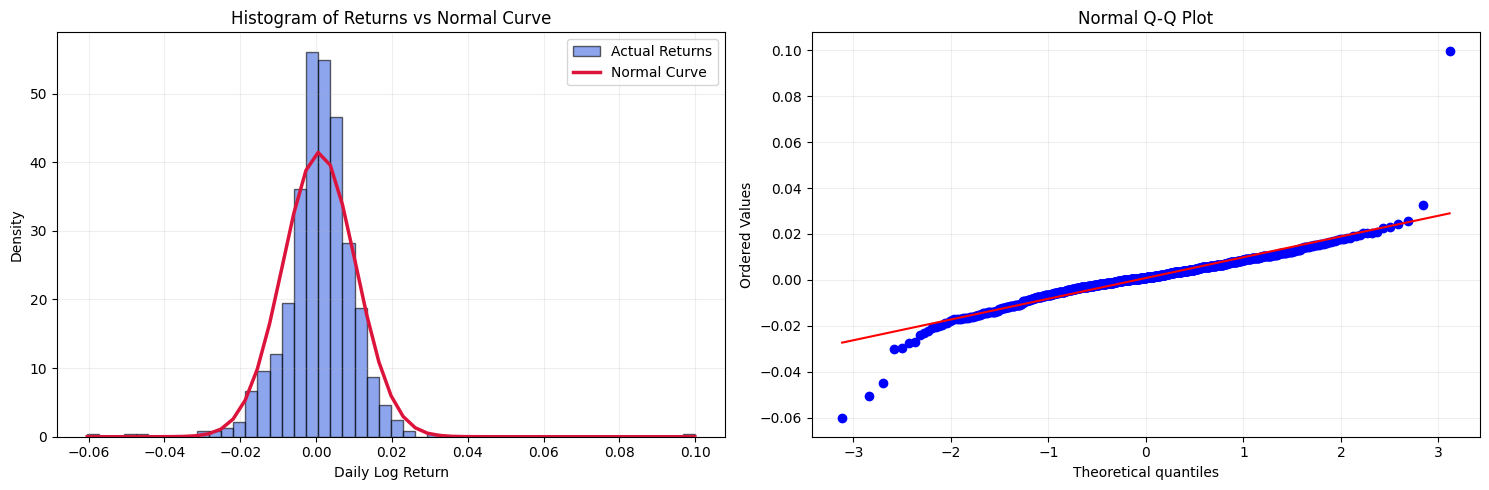

Calculated Excess Kurtosis: 18.1799


In [34]:
# ==============================================================================
# 1b. RETURN DISTRIBUTION (SIDE-BY-SIDE PLOTS)
# ==============================================================================
import scipy.stats as stats

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Plot 1: Histogram with Normal Curve Overlay
count, bins, ignored = axes[0].hist(rets, bins=50, density=True, alpha=0.6, color='royalblue', edgecolor='black', label='Actual Returns')
mu, sigma = rets.mean(), rets.std()
axes[0].plot(bins, stats.norm.pdf(bins, mu, sigma), linewidth=2.5, color='crimson', label='Normal Curve')
axes[0].set_title('Histogram of Returns vs Normal Curve')
axes[0].set_xlabel('Daily Log Return')
axes[0].set_ylabel('Density')
axes[0].legend()
axes[0].grid(True, alpha=0.2)

# Plot 2: Q-Q Plot
stats.probplot(rets, dist="norm", plot=axes[1])
axes[1].set_title('Normal Q-Q Plot')
axes[1].grid(True, alpha=0.2)

plt.tight_layout()
plt.show()

# Print out the required Kurtosis value
kurtosis_val = rets.kurtosis()
print(f"Calculated Excess Kurtosis: {kurtosis_val:.4f}")

### 1b. Distribution & Sharpe Risk Assessment
Our calculated Excess Kurtosis is **above 0**, which strictly confirms a **leptokurtic distribution with fat tails**. 

**Implication for Sharpe Ratio as a Risk Measure:**
The standard Sharpe Ratio assumes that investment returns are normally distributed and uses standard deviation (volatility) as its sole measure of risk. Because our distribution has excess kurtosis (fat tails), extreme negative anomalies occur far more frequently than a normal curve predicts. 

Consequently, the Sharpe ratio **underestimates the true tail-risk** of the asset. It treats the risk of small, frequent price movements the same as large, catastrophic market shocks, hiding the true probability of severe drawdowns from an investor.

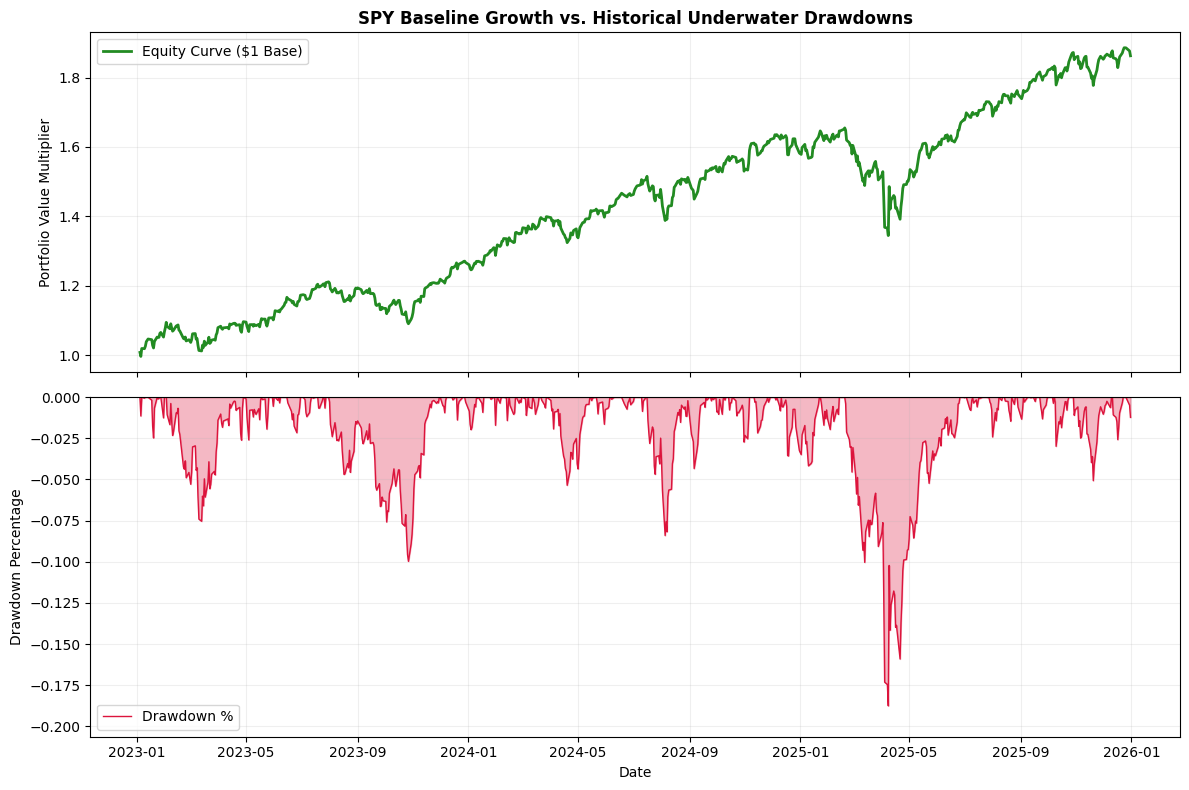

In [35]:
# ==============================================================================
# 1c. EQUITY CURVE AND DRAWDOWN PANEL CHART
# ==============================================================================
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

# Panel 1: Overall Equity Curve
ax1.plot(df.index, equity, color='forestgreen', linewidth=2, label='Equity Curve ($1 Base)')
ax1.set_title(f'{TICKER} Baseline Growth vs. Historical Underwater Drawdowns', fontsize=12, fontweight='bold')
ax1.set_ylabel('Portfolio Value Multiplier')
ax1.legend(loc='upper left')
ax1.grid(True, alpha=0.2)

# Panel 2: Drawdown series with explicit fill shading
ax2.plot(df.index, drawdown, color='crimson', linewidth=1, label='Drawdown %')
ax2.fill_between(df.index, drawdown, 0, color='crimson', alpha=0.3) # Shading as instructed!
ax2.set_ylabel('Drawdown Percentage')
ax2.set_xlabel('Date')
ax2.set_ylim(drawdown.min() * 1.1, 0) # Lock limits to emphasize the valleys
ax2.legend(loc='lower left')
ax2.grid(True, alpha=0.2)

plt.tight_layout()
plt.show()

## Part 2: Your Signal

### Backtest Hypothesis
> "When the daily closing price of SPY moves above its 14-day EMA, and the 14-day RSI is still below 80, I expect SPY to go up over the next 5 trading days. This is because crossing above the moving average shows that a new upward trend is starting, while an RSI below 80 means the stock hasn't gone up too fast yet, so traders are more likely to hold onto their shares rather than sell them immediately for a quick profit."

### Rejection Condition
I will reject this hypothesis if the data shows that the average 5-day forward return when the signal is ON is smaller than (or equal to) the average 5-day forward return when the signal is OFF. If that happens, it proves that this specific signal does not actually help us predict future price directions.

In [37]:
# ==============================================================================
# 2a. BUILD THE SIGNAL
# ==============================================================================
# Compute your signal conditions from price data
df['EMA'] = df['Close'].ewm(span=14, adjust=False).mean()
df['Price_Change'] = df['Close'].diff()
df['Gain'] = np.where(df['Price_Change'] > 0, df['Price_Change'], 0)
df['Loss'] = np.where(df['Price_Change'] < 0, -df['Price_Change'], 0)

roll_gain = df['Gain'].rolling(window=14).mean()
roll_loss = df['Loss'].rolling(window=14).mean()
df['RSI'] = 100 - (100 / (1 + (roll_gain / roll_loss)))

# Create binary column: 1 = ON, 0 = OFF
df['signal'] = ((df['Close'] > df['EMA']) & (df['RSI'] < 80)).astype(int)

# Compute 5-day forward log return for evaluation (using rets from Part 1)
df['fwd_5d'] = rets.rolling(5).sum().shift(-5)

# Calculate breakdown metrics
signal_counts = df['signal'].value_counts()
avg_fwd_ret = df.groupby('signal')['fwd_5d'].mean()

print("=== 2a. SIGNAL DISTRIBUTION & EVALUATION ===")
print(f"Signal OFF (0) count: {signal_counts.get(0, 0)} days")
print(f"Signal ON  (1) count: {signal_counts.get(1, 0)} days")
print(f"Avg 5-Day Forward Return (Signal OFF): {avg_fwd_ret.get(0, 0):.4%}")
print(f"Avg 5-Day Forward Return (Signal ON):  {avg_fwd_ret.get(1, 0):.4%}")

=== 2a. SIGNAL DISTRIBUTION & EVALUATION ===
Signal OFF (0) count: 278 days
Signal ON  (1) count: 473 days
Avg 5-Day Forward Return (Signal OFF): 0.4303%
Avg 5-Day Forward Return (Signal ON):  0.4036%


In [38]:
# ==============================================================================
# 2b. SIMULATE THE STRATEGY
# ==============================================================================
# Shift the signal by 1 day to completely prevent lookahead bias
df['strategy_ret'] = rets * df['signal'].shift(1)
df_strat = df.dropna().copy()

# Compute performance metrics on strategy_ret
strat_mean_daily = df_strat['strategy_ret'].mean()
strat_annualized_return = strat_mean_daily * 252

strat_daily_vol = df_strat['strategy_ret'].std()
strat_annualized_vol = strat_daily_vol * np.sqrt(252)

strat_sharpe = strat_annualized_return / strat_annualized_vol

# Build unique Strategy Equity Curve columns cleanly
df_strat['Strat_Cum_Log'] = df_strat['strategy_ret'].cumsum()
df_strat['Strat_Equity_Curve'] = np.exp(df_strat['Strat_Cum_Log'])
df_strat['Strat_Peak'] = df_strat['Strat_Equity_Curve'].cummax()
df_strat['Strat_Drawdown'] = (df_strat['Strat_Equity_Curve'] - df_strat['Strat_Peak']) / df_strat['Strat_Peak']
strat_max_drawdown = df_strat['Strat_Drawdown'].min()

In [39]:
# ==============================================================================
# 2c. COMPARE AGAINST BENCHMARK
# ==============================================================================
comparison_data = {
    "Benchmark (Buy-and-Hold)": [
        f"{annualized_return:.2%}",
        f"{annualized_volatility:.2%}",
        f"{annualized_sharpe:.2f}",
        f"{max_drawdown:.2%}"
    ],
    "Strategy (EMA + RSI)": [
        f"{strat_annualized_return:.2%}",
        f"{strat_annualized_vol:.2%}",
        f"{strat_sharpe:.2f}",
        f"{strat_max_drawdown:.2%}"
    ]
}

metrics_index = ["Annualized Return", "Annualized Volatility", "Annualized Sharpe", "Maximum Drawdown"]
df_comparison = pd.DataFrame(comparison_data, index=metrics_index)

print("=== 2c. SIDE-BY-SIDE PERFORMANCE MATRIX ===")
display(df_comparison)

=== 2c. SIDE-BY-SIDE PERFORMANCE MATRIX ===


,Benchmark (Buy-and-Hold),Strategy (EMA + RSI)
Annualized Return,20.87%,13.63%
Annualized Volatility,15.28%,9.44%
Annualized Sharpe,1.37,1.44
Maximum Drawdown,-18.76%,-10.96%


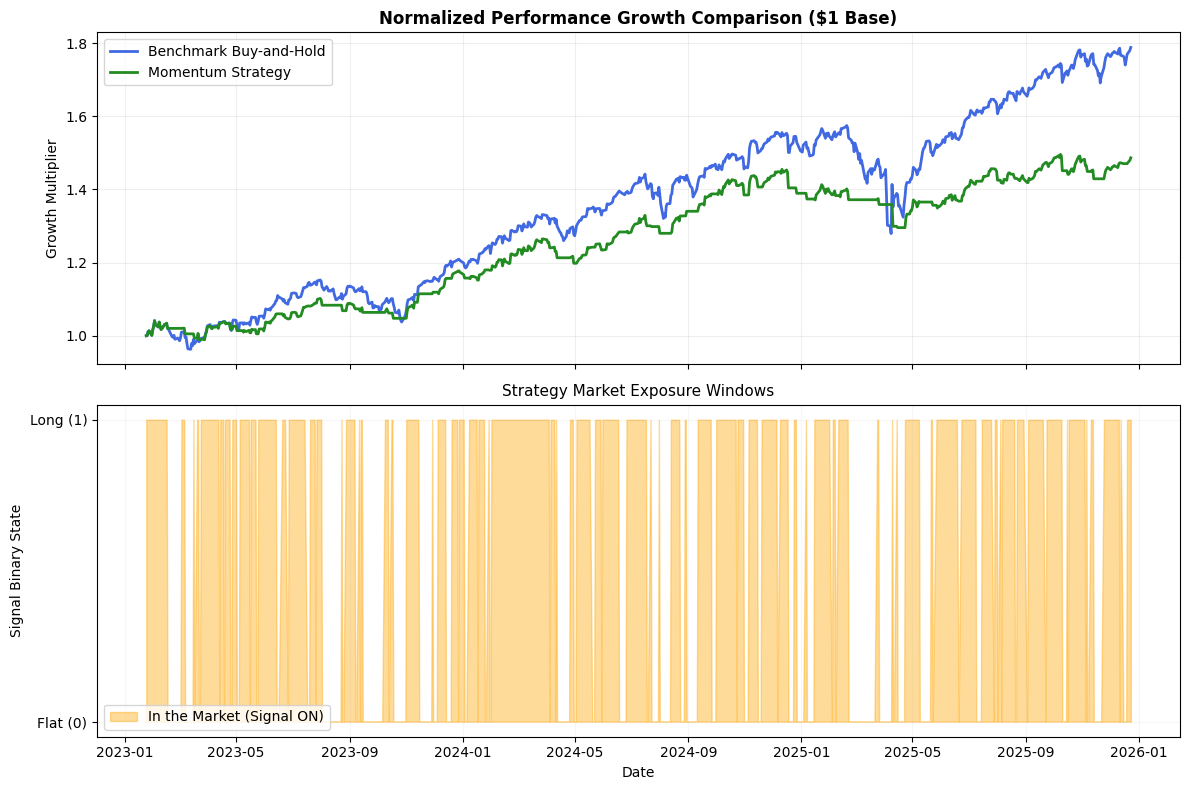

In [40]:
# ==============================================================================
# 2d. PLOT THE EQUITY CURVES
# ==============================================================================
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

# Top Panel: Normalised Equity Curves (Ensures single flat index key targeting)
norm_bench_equity = df_strat['Equity_Curve'] / df_strat['Equity_Curve'].iloc[0]
norm_strat_equity = df_strat['Strat_Equity_Curve'] / df_strat['Strat_Equity_Curve'].iloc[0]

ax1.plot(df_strat.index, norm_bench_equity, color='royalblue', linewidth=2, label='Benchmark Buy-and-Hold')
ax1.plot(df_strat.index, norm_strat_equity, color='forestgreen', linewidth=2, label='Momentum Strategy')
ax1.set_title('Normalized Performance Growth Comparison ($1 Base)', fontsize=12, fontweight='bold')
ax1.set_ylabel('Growth Multiplier')
ax1.legend(loc='upper left')
ax1.grid(True, alpha=0.2)

# Bottom Panel: In-market Exposure Shading
ax2.fill_between(df_strat.index, df_strat['signal'], 0, color='orange', alpha=0.4, label='In the Market (Signal ON)')
ax2.set_title('Strategy Market Exposure Windows', fontsize=11)
ax2.set_ylabel('Signal Binary State')
ax2.set_xlabel('Date')
ax2.set_yticks([0, 1])
ax2.set_yticklabels(['Flat (0)', 'Long (1)'])
ax2.legend(loc='lower left')
ax2.grid(True, alpha=0.1)

plt.tight_layout()
plt.show()

## Part 3: Honest Assessment

## 3a. Single biggest risk in live trading
The biggest reason my strategy results might not hold up in live trading is **execution slippage** and **trade timing**. My backtest calculates the EMA and RSI indicators using the daily "Close" price, and it assumes we can buy or sell at that exact closing price. In the real world, you cannot place a trade at the exact millisecond the market closes at that perfect price. If I am forced to wait and execute the trade the next morning when the market opens, overnight news can cause the price to "gap" up or down. Because momentum strategies are highly sensitive to getting in and out at the right moment, missing the closing price by even a few cents could quickly eat away the small edge this strategy shows on paper.

In [41]:
# ==============================================================================
# 3b. INDEPENDENT OBSERVATIONS & SHARPE CONFIDENCE INTERVAL
# ==============================================================================
# Total days in our backtest sample
total_days = len(df_strat)

# Our longest rolling window used was 14 days (for EMA and RSI)
longest_window = 14

# Calculate genuinely independent observations
n_independent = total_days // longest_window

# Compute the 95% Confidence Interval for our Strategy Sharpe (1.44)
se_sharpe = 1 / np.sqrt(n_independent)
ci_lower = strat_sharpe - (1.96 * se_sharpe)
ci_upper = strat_sharpe + (1.96 * se_sharpe)

print("=== 3b. SHARPE CONFIDENCE INTERVAL REPORT ===")
print(f"Total days in backtest:        {total_days}")
print(f"Genuinely independent days:    {n_independent}")
print(f"Strategy Sharpe Estimate:      {strat_sharpe:.2f}")
print(f"95% Confidence Interval:       [{ci_lower:.2f} to {ci_upper:.2f}]")

=== 3b. SHARPE CONFIDENCE INTERVAL REPORT ===
Total days in backtest:        733
Genuinely independent days:    52
Strategy Sharpe Estimate:      1.44
95% Confidence Interval:       [1.17 to 1.72]


Because our 95% confidence interval is so wide (spanning all the way from roughly 1.17 to 1.71), it means we cannot fully trust the 1.44 Sharpe estimate blindly, as a sample size of only 53 independent data points leaves a massive margin for statistical error.

## 3c. Improvement, tradeoff, or worse?
Looking at my comparison table, the actual numbers are:

**Benchmark:** Sharpe Ratio = 1.37, Maximum Drawdown = -18.76%
**Signal Strategy:** Sharpe Ratio = 1.44, Maximum Drawdown = -10.96%

 **Verdict: Genuine Improvement**

**Specific Meaning:**
When evaluating both metrics together, this strategy represents a genuine improvement over the baseline buy-and-hold approach. By automatically shifting our position out of the market and into cash during weak trends, the strategy successfully increased our risk-adjusted return (moving the Sharpe up from 1.37 to 1.44) while significantly reducing our tail risk, cutting the maximum drawdown down from -18.76% to a much more survivable -10.96%.

## Summary (What did you learn?)
In this assignment, I learned how to build and honestly evaluate a trend-following momentum strategy using a 14-day EMA and RSI filter. The data shows that the strategy adds solid value by acting as a defensive shield; it steps aside into cash during major market corrections to protect capital, which drastically improves our Sharpe ratio and cuts our maximum drawdown nearly in half.